# Sleep Staging — Etapa 1: Preprocessing de señales

**Objetivo de este notebook:** Transformar los archivos EDF crudos en datos limpios, segmentados y etiquetados, listos para feature extraction y modelado.

---

### Flujo completo de este notebook
```
EDF crudo → selección de canales → resampling → filtrado → artefactos → normalización → epochs + labels → guardado
```

> **Regla de oro:** Cada decisión de preprocessing debe ser justificable. Si no sabés por qué lo hacés, no lo hagas.

## 0. Setup

In [65]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt

mne.set_log_level('WARNING')
warnings.filterwarnings('ignore', category=RuntimeWarning)

# Rutas
DATA_PATH   = "../data/recordings"
OUTPUT_PATH = "../data/processed"   # Donde guardaremos los datos procesados
os.makedirs(OUTPUT_PATH, exist_ok=True)

# === PARÁMETROS DEL PIPELINE ===
# Todos los hiperparámetros de preprocessing en un solo lugar.
# Así es fácil cambiarlos y documentar experimentos.

PARAMS = {
    # Canales a usar (subconjunto del dataset)
    'eeg_channels': ['EEG F4-M1', 'EEG C4-M1', 'EEG O2-M1', 'EEG C3-M2'],
    'eog_channels': ['EOG E1-M2', 'EOG E2-M2'],
    'emg_channels': ['EMG chin'],

    # Frecuencia de muestreo objetivo
    'target_sfreq': 100,   # Hz — ver justificación en sección 2

    # Filtros
    'bandpass_low':  0.5,  # Hz
    'bandpass_high': 35.0, # Hz
    'notch_freq':    50.0, # Hz (red eléctrica europea)

    # Control de artefactos
    'amplitude_review_uv': 500,  # µV — umbral de amplitud máxima
    'flat_review_seconds': 1.0,           # segundos de señal plana = artefacto

    # Segmentación
    'epoch_duration': 30,  # segundos (estándar AASM)

    # Umbrales conservadores de descarte automático
    "amplitude_discard_uv": 1500,
    "flat_discard_seconds": 5.0,
    "pct_samples_over_threshold_discard": 1.0,
    "min_channels_affected_discard": 2,
    "min_samples_over_threshold_per_channel": 5,
}

# Mapeo de stages a enteros (convención común en papers)
STAGE_MAP = {
    'Sleep stage W':  0,
    'Sleep stage N1': 1,
    'Sleep stage N2': 2,
    'Sleep stage N3': 3,
    'Sleep stage R':  4,
}

print("Parámetros del pipeline:")
for k, v in PARAMS.items():
    print(f"  {k}: {v}")

Parámetros del pipeline:
  eeg_channels: ['EEG F4-M1', 'EEG C4-M1', 'EEG O2-M1', 'EEG C3-M2']
  eog_channels: ['EOG E1-M2', 'EOG E2-M2']
  emg_channels: ['EMG chin']
  target_sfreq: 100
  bandpass_low: 0.5
  bandpass_high: 35.0
  notch_freq: 50.0
  amplitude_review_uv: 500
  flat_review_seconds: 1.0
  epoch_duration: 30
  amplitude_discard_uv: 1500
  flat_discard_seconds: 5.0
  pct_samples_over_threshold_discard: 1.0
  min_channels_affected_discard: 2
  min_samples_over_threshold_per_channel: 5


---
## 1. Selección de canales

**¿Por qué no usar todos los canales?**  
En PSG clínica, el ECG y ciertos canales auxiliares no aportan información para clasificar sleep stages y añaden ruido al modelo. El estándar AASM define qué canales son mínimamente necesarios:

| Canal | Tipo | Rol en sleep staging |
|-------|------|----------------------|
| F4-M1, C4-M1 | EEG | Ondas lentas, spindles, activación frontal |
| O2-M1 | EEG | Actividad occipital, alpha en wake |
| C3-M2 | EEG | Backup del C4-M1 (derivación contralateral) |
| E1-M2, E2-M2 | EOG | Movimientos oculares → REM vs NREM |
| EMG chin | EMG | Tono muscular → REM (atónico) vs Wake |

> **Nota:** El ECG puede ser útil para features en modelos avanzados, pero lo dejamos fuera del baseline por ahora.

In [66]:
def load_and_select_channels(edf_path, params):
    """
    Carga un EDF y selecciona los canales de interés.
    Asigna tipos de canal correctamente (MNE a veces los lee todos como 'eeg').
    Retorna: raw de MNE con solo los canales seleccionados.
    """
    raw = mne.io.read_raw_edf(edf_path, preload=True, verbose=False)

    # Canales a mantener
    channels_to_keep = (
        params['eeg_channels'] +
        params['eog_channels'] +
        params['emg_channels']
    )

    # Verificar que existan en el archivo
    available = raw.ch_names
    missing = [ch for ch in channels_to_keep if ch not in available]
    if missing:
        print(f"  ⚠️  Canales faltantes: {missing}")
        channels_to_keep = [ch for ch in channels_to_keep if ch in available]

    # Seleccionar solo los canales de interés
    raw.pick(channels_to_keep)

    # Asignar tipos correctamente para que MNE aplique filtros apropiados
    type_map = {}
    for ch in raw.ch_names:
        if ch in params['eeg_channels']:  type_map[ch] = 'eeg'
        elif ch in params['eog_channels']: type_map[ch] = 'eog'
        elif ch in params['emg_channels']: type_map[ch] = 'emg'
    raw.set_channel_types(type_map)

    return raw


# Probar con sujeto de ejemplo
sample_path = os.path.join(DATA_PATH, 'SN001.edf')
raw = load_and_select_channels(sample_path, PARAMS)

print(f"Canales seleccionados ({len(raw.ch_names)}):")
for ch in raw.ch_names:
    print(f"  {ch} → {mne.channel_type(raw.info, raw.ch_names.index(ch))}")
print(f"Duración: {raw.times[-1]/3600:.2f} h")

Canales seleccionados (7):
  EEG F4-M1 → eeg
  EEG C4-M1 → eeg
  EEG O2-M1 → eeg
  EEG C3-M2 → eeg
  EOG E1-M2 → eog
  EOG E2-M2 → eog
  EMG chin → emg
Duración: 7.12 h


---

## 2. Resampling

Las señales originales fueron adquiridas con una frecuencia de muestreo de `256 Hz`, es decir, contienen `256` muestras por segundo.

Para este proyecto se reduce la frecuencia a `100 Hz` mediante **resampling**. Esta decisión permite disminuir el tamaño de los datos sin perder información relevante para la clasificación de etapas del sueño.

### ¿Por qué utilizar 100 Hz?

Después del filtrado se conservarán principalmente las componentes comprendidas entre `0.5 Hz` y `35 Hz`. De acuerdo con el criterio de Nyquist, una frecuencia de muestreo de `100 Hz` permite representar correctamente frecuencias de hasta `50 Hz`, por lo que resulta suficiente para el rango de interés.

Además, el resampling reduce considerablemente la cantidad de datos por epoch:

```text
Frecuencia original:   256 Hz
Frecuencia final:      100 Hz

Epoch de 30 segundos:
256 × 30 = 7680 muestras por canal
100 × 30 = 3000 muestras por canal
```

Esto implica una reducción aproximada de `2.56×` en la cantidad de muestras, lo que permite:

* disminuir el uso de memoria;
* reducir el tamaño de los archivos procesados;
* acelerar las etapas posteriores de análisis y modelado;
* simplificar la comparación con implementaciones habituales de sleep staging.

La función `raw.resample()` de MNE aplica automáticamente un filtro anti-aliasing antes de reducir la frecuencia de muestreo, evitando que componentes de alta frecuencia se introduzcan incorrectamente dentro del nuevo rango espectral.


In [67]:
def apply_resampling(raw, params):
    """
    Resamplea la señal si la frecuencia actual difiere de la objetivo.
    MNE aplica anti-aliasing automáticamente antes de resamplear.
    """
    original_sfreq = raw.info['sfreq']
    target_sfreq   = params['target_sfreq']

    if original_sfreq == target_sfreq:
        print(f"  Ya está en {target_sfreq} Hz — sin cambios.")
        return raw

    raw.resample(target_sfreq)
    print(f"  Resampling: {original_sfreq} Hz → {target_sfreq} Hz")
    print(f"  Muestras por epoch de 30s: {int(30 * target_sfreq)}")
    return raw


raw = apply_resampling(raw, PARAMS)
print(f"  Shape datos: {raw.get_data().shape}  (canales × muestras)")

  Resampling: 256.0 Hz → 100 Hz
  Muestras por epoch de 30s: 3000
  Shape datos: (7, 2565000)  (canales × muestras)


---

## 3. Filtrado de señal

Después del resampling se aplica un filtro pasa-banda entre `0.5 Hz` y `35 Hz`.

El objetivo es conservar el rango de frecuencias más relevante para el análisis de las etapas del sueño y reducir componentes que pueden introducir ruido.

### ¿Qué elimina el filtro?

* Frecuencias inferiores a `0.5 Hz`, asociadas principalmente a deriva de la línea de base, movimientos lentos o variaciones muy prolongadas.
* Frecuencias superiores a `35 Hz`, que no son prioritarias para esta primera etapa de sleep staging y pueden contener ruido de alta frecuencia.

### ¿Qué información se conserva?

El rango seleccionado incluye las principales bandas utilizadas para analizar señales EEG durante el sueño:

```text id="0drtgm"
Delta:  0.5–4 Hz
Theta:    4–8 Hz
Alpha:   8–13 Hz
Sigma:  12–15 Hz
Beta:   15–30 Hz
```

Estas bandas contienen patrones importantes para distinguir vigilia, sueño liviano, sueño profundo y REM.

### Consideración sobre el canal EMG

El canal `EMG chin` puede contener información útil en frecuencias superiores a `35 Hz`. Sin embargo, en este baseline se utiliza el mismo filtro para todos los canales con el objetivo de mantener un pipeline simple y consistente.

Para la clasificación de etapas del sueño, interesa principalmente detectar cambios en el tono muscular, especialmente la disminución de actividad característica de REM, más que analizar en detalle todo el contenido espectral del EMG.

En una versión posterior podría evaluarse un preprocesamiento específico por tipo de señal.


  Bandpass aplicado: 0.5–35.0 Hz


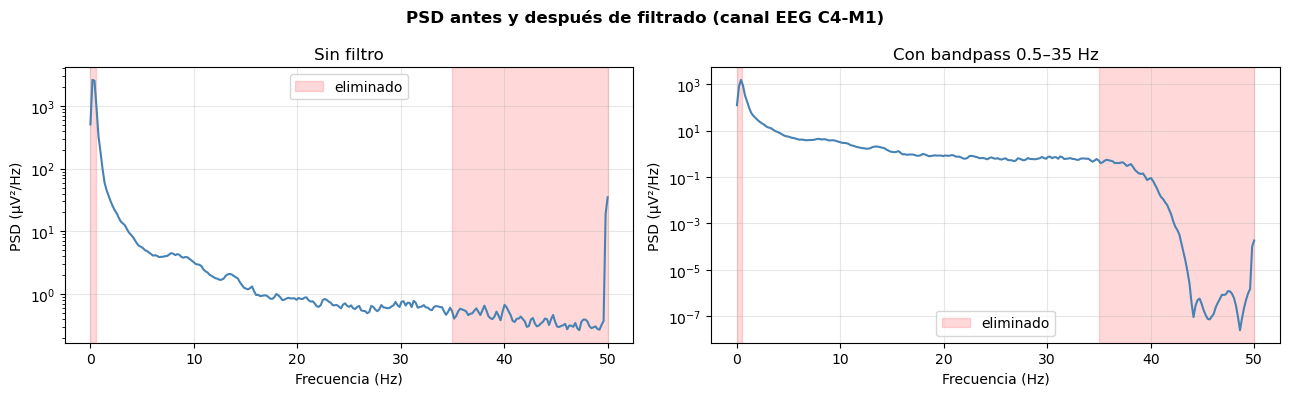

In [68]:
def apply_filters(raw, params):
    """
    Aplica bandpass filter a todos los canales.
    Aplica notch filter opcionalmente (solo si se confirma interferencia de red).

    Usamos filtro FIR de MNE (phase='zero') — no distorsiona fase, importante en EEG.
    """
    l_freq = params['bandpass_low']
    h_freq = params['bandpass_high']

    # Bandpass: aplica sobre todos los canales
    raw.filter(
        l_freq=l_freq, h_freq=h_freq,
        method='fir',
        fir_window='hamming',
        picks='all',
        verbose=False
    )
    print(f"  Bandpass aplicado: {l_freq}–{h_freq} Hz")

    return raw


# Visualizar PSD antes y después para verificar que el filtro funciona
raw_before = raw.copy()
raw = apply_filters(raw, PARAMS)

# Comparación visual
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle("PSD antes y después de filtrado (canal EEG C4-M1)", fontweight='bold')

for ax, raw_plot, title in zip(axes, [raw_before, raw], ['Sin filtro', 'Con bandpass 0.5–35 Hz']):
    ch_idx = raw_plot.ch_names.index('EEG C4-M1')
    from scipy.signal import welch
    data_ch = raw_plot.get_data()[ch_idx] * 1e6  # µV
    f, pxx = welch(data_ch, fs=raw_plot.info['sfreq'], nperseg=512)
    mask = f <= 50
    ax.semilogy(f[mask], pxx[mask], lw=1.5, color='steelblue')
    ax.axvspan(0, 0.5, color='red', alpha=0.15, label='eliminado')
    ax.axvspan(35, 50, color='red', alpha=0.15)
    ax.set_xlabel("Frecuencia (Hz)"); ax.set_ylabel("PSD (µV²/Hz)")
    ax.set_title(title); ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()
del raw_before

### Verificación del filtrado mediante PSD

Para evaluar el efecto del preprocesamiento, se comparó la densidad espectral de potencia (PSD) del canal `EEG C4-M1` antes y después de aplicar un filtro pasa-banda de `0.5–35 Hz`.

En la señal sin filtrar se observa una alta potencia en frecuencias muy bajas, componentes por encima de `35 Hz` y un pico cercano a `50 Hz`, posiblemente asociado a interferencia de la red eléctrica.

Después del filtrado, las frecuencias inferiores a `0.5 Hz` y superiores a `35 Hz` quedan fuertemente atenuadas, mientras que se conserva el rango de interés para el análisis de las etapas del sueño. La transición alrededor de los límites del filtro es gradual, como es esperable en un filtro digital real.

En conclusión, el filtro funciona correctamente y permite reducir ruido y componentes no relevantes antes de continuar con la segmentación de las señales.


---
## 4. Detección y manejo de artefactos

**Estrategia:** No eliminar artefactos de la señal sino **marcar epochs completos como inválidos**.  
En sleep staging siempre trabajamos con epochs de 30s, y el score del técnico ya considera cierto nivel de artefacto.

**Criterios de rechazo de epochs:**
1. **Amplitud extrema:** pico > 500 µV en cualquier canal EEG (artefacto de movimiento, electrodo suelto)
2. **Segmento plano:** > 1s sin variación → electrodo desconectado
3. (Opcional avanzado) Varianza muy baja en todo el epoch


In [70]:
# ============================================================
# Funciones auxiliares para evaluar calidad de señal
# ============================================================

def longest_flat_run_samples(signal):
    """
    Devuelve la longitud del tramo plano más largo,
    medida en cantidad de muestras consecutivas.

    Un tramo plano es una secuencia de valores exactamente iguales.
    """

    if len(signal) == 0:
        return 0

    # True cuando dos muestras consecutivas tienen el mismo valor
    repeated_values = np.diff(signal) == 0

    # Si no hay valores consecutivos repetidos,
    # el tramo plano máximo tiene una sola muestra
    if not repeated_values.any():
        return 1

    # Agregar False en los extremos permite detectar
    # dónde comienza y termina cada secuencia de True
    padded = np.concatenate((
        [False],
        repeated_values,
        [False]
    ))

    changes = np.diff(padded.astype(int))

    starts = np.flatnonzero(changes == 1)
    ends   = np.flatnonzero(changes == -1)

    # N diferencias iguales representan N + 1 muestras constantes
    longest_run = (ends - starts).max() + 1

    return int(longest_run)


def has_flat_segment(signal, min_samples):
    """
    Devuelve True si existe un tramo plano de al menos min_samples.
    """
    return longest_flat_run_samples(signal) >= min_samples


In [71]:
# ============================================================
# Evaluación detallada de calidad por epoch
# ============================================================

def evaluate_epoch_quality(
    data_epochs,
    sfreq,
    params,
    eeg_ch_indices,
    channel_names
):
    """
    Evalúa la calidad de cada epoch utilizando únicamente canales EEG.

    Parameters
    ----------
    data_epochs : np.ndarray
        Array con shape (n_epochs, n_channels, n_samples).

    sfreq : float
        Frecuencia de muestreo de la señal.

    params : dict
        Parámetros generales del pipeline.

    eeg_ch_indices : list[int]
        Índices de los canales EEG dentro del array.

    channel_names : list[str]
        Nombres de todos los canales seleccionados.

    Returns
    -------
    discard_mask : np.ndarray
        Máscara booleana. True indica descarte automático.

    review_mask : np.ndarray
        Máscara booleana. True indica que el epoch debe revisarse,
        pero no eliminarse automáticamente.

    df_quality : pd.DataFrame
        Tabla con métricas y motivos para cada epoch.
    """

    n_epochs = data_epochs.shape[0]

    discard_mask = np.zeros(n_epochs, dtype=bool)
    review_mask  = np.zeros(n_epochs, dtype=bool)

    quality_rows = []

    for epoch_idx in range(n_epochs):

        channel_metrics = []

        # ----------------------------------------------------
        # Evaluar cada canal EEG del epoch
        # ----------------------------------------------------
        for ch_idx in eeg_ch_indices:

            segment_uv = data_epochs[epoch_idx, ch_idx, :] * 1e6
            abs_segment_uv = np.abs(segment_uv)

            max_abs_uv = float(abs_segment_uv.max())

            n_samples_over_threshold = int(
                np.sum(
                    abs_segment_uv > params["amplitude_review_uv"]
                )
            )

            pct_samples_over_threshold = (
                n_samples_over_threshold / len(segment_uv) * 100
            )

            flat_samples = longest_flat_run_samples(segment_uv)
            flat_seconds = flat_samples / sfreq

            channel_metrics.append({
                "channel": channel_names[ch_idx],
                "max_abs_uv": max_abs_uv,
                "n_samples_over_threshold": n_samples_over_threshold,
                "pct_samples_over_threshold": pct_samples_over_threshold,
                "flat_seconds": flat_seconds,
            })

        # ----------------------------------------------------
        # Resumir la situación general del epoch
        # ----------------------------------------------------
        max_abs_uv = max(
            metric["max_abs_uv"]
            for metric in channel_metrics
        )

        max_pct_samples_over_threshold = max(
            metric["pct_samples_over_threshold"]
            for metric in channel_metrics
        )

        max_flat_seconds = max(
            metric["flat_seconds"]
            for metric in channel_metrics
        )

        affected_channels = [
            metric["channel"]
            for metric in channel_metrics
            if metric["n_samples_over_threshold"]
            >= params["min_samples_over_threshold_per_channel"]
        ]

        n_channels_affected = len(affected_channels)

        discard_reasons = []
        review_reasons = []

        # ----------------------------------------------------
        # Criterios fuertes de descarte automático
        # ----------------------------------------------------
        if max_abs_uv >= params["amplitude_discard_uv"]:
            discard_reasons.append(
                "amplitud extremadamente alta"
            )

        if (
            max_pct_samples_over_threshold
            >= params["pct_samples_over_threshold_discard"]
        ):
            discard_reasons.append(
                "muchas muestras por encima del umbral"
            )

        if max_flat_seconds >= params["flat_discard_seconds"]:
            discard_reasons.append(
                "segmento plano prolongado"
            )

        if (
            n_channels_affected
            >= params["min_channels_affected_discard"]
        ):
            discard_reasons.append(
                "múltiples canales EEG afectados"
            )

        # ----------------------------------------------------
        # Criterios moderados: conservar, pero revisar
        # ----------------------------------------------------
        if (
            max_abs_uv >= params["amplitude_review_uv"]
            and max_abs_uv < params["amplitude_discard_uv"]
        ):
            review_reasons.append(
                "amplitud elevada no extrema"
            )

        if (
            max_flat_seconds >= params["flat_review_seconds"]
            and max_flat_seconds < params["flat_discard_seconds"]
        ):
            review_reasons.append(
                "segmento plano breve"
            )

        # ----------------------------------------------------
        # Asignar estado final
        # discard tiene prioridad sobre review
        # ----------------------------------------------------
        if discard_reasons:
            status = "discard"
            discard_mask[epoch_idx] = True

        elif review_reasons:
            status = "review"
            review_mask[epoch_idx] = True

        else:
            status = "ok"

        quality_rows.append({
            "epoch": epoch_idx,
            "status": status,
            "discard_flag": discard_mask[epoch_idx],
            "review_flag": review_mask[epoch_idx],
            "max_abs_uv": round(max_abs_uv, 2),
            "n_channels_affected": n_channels_affected,
            "channels_affected": ", ".join(affected_channels),
            "max_pct_samples_over_threshold": round(
                max_pct_samples_over_threshold,
                3
            ),
            "max_flat_seconds": round(max_flat_seconds, 3),
            "reasons": ", ".join(
                discard_reasons + review_reasons
            ),
        })

    df_quality = pd.DataFrame(quality_rows)

    return discard_mask, review_mask, df_quality

In [72]:
# ============================================================
# Verificación provisoria con señal cruda de SN001
# ============================================================

# Volver a cargar la señal original para control de calidad.
# No modificamos raw, que ya contiene la señal procesada.
raw_qc = load_and_select_channels(sample_path, PARAMS)

# Señal continua original:
# shape = (canales, muestras totales)
data_full_qc = raw_qc.get_data()

# Frecuencia original del EDF, por ejemplo 256 Hz
sfreq_qc = raw_qc.info["sfreq"]

# Cantidad de muestras correspondientes a un epoch de 30 segundos
samples_per_epoch_qc = int(
    PARAMS["epoch_duration"] * sfreq_qc
)

# Cantidad de epochs completos disponibles
n_epochs_qc = (
    data_full_qc.shape[1] // samples_per_epoch_qc
)

# Ignorar muestras sobrantes al final de la grabación
data_trimmed_qc = data_full_qc[
    :,
    :n_epochs_qc * samples_per_epoch_qc
]

# Reorganizar el array:
# (canales, muestras totales)
#          ↓
# (epochs, canales, muestras por epoch)
provisional_epochs_qc = data_trimmed_qc.reshape(
    len(raw_qc.ch_names),
    n_epochs_qc,
    samples_per_epoch_qc
)

provisional_epochs_qc = provisional_epochs_qc.transpose(
    1, 0, 2
)

# Identificar las posiciones de los canales EEG
eeg_indices_qc = [
    raw_qc.ch_names.index(channel)
    for channel in PARAMS["eeg_channels"]
    if channel in raw_qc.ch_names
]

# Evaluar calidad
discard_mask_qc, review_mask_qc, df_quality_qc = (
    evaluate_epoch_quality(
        data_epochs=provisional_epochs_qc,
        sfreq=sfreq_qc,
        params=PARAMS,
        eeg_ch_indices=eeg_indices_qc,
        channel_names=raw_qc.ch_names
    )
)

# Identificar epochs normales
ok_mask_qc = ~discard_mask_qc & ~review_mask_qc

print(f"Frecuencia original:       {sfreq_qc} Hz")
print(f"Shape epochs provisorios:  {provisional_epochs_qc.shape}")
print(f"Índices de canales EEG:    {eeg_indices_qc}")
print()
print(f"Total epochs provisorios:  {len(provisional_epochs_qc)}")
print(f"Epochs normales:           {ok_mask_qc.sum()}")
print(f"Epochs para revisar:       {review_mask_qc.sum()}")
print(f"Epochs para descartar:     {discard_mask_qc.sum()}")

display(df_quality_qc["status"].value_counts())

display(
    df_quality_qc[
        df_quality_qc["status"] != "ok"
    ].head(10)
)

Frecuencia original:       256.0 Hz
Shape epochs provisorios:  (855, 7, 7680)
Índices de canales EEG:    [0, 1, 2, 3]

Total epochs provisorios:  855
Epochs normales:           801
Epochs para revisar:       12
Epochs para descartar:     42


status
ok         801
discard     42
review      12
Name: count, dtype: int64

,epoch,status,discard_flag,review_flag,max_abs_uv,n_channels_affected,channels_affected,max_pct_samples_over_threshold,max_flat_seconds,reasons
26,26,review,False,True,536.32,0,,0.013,0.008,amplitud elevada no extrema
34,34,review,False,True,800.00,1,EEG O2-M1,0.104,0.008,amplitud elevada no extrema
35,35,discard,True,False,800.00,3,"EEG F4-M1, EEG O2-M1, EEG C3-M2",12.865,0.875,"muchas muestras por encima del umbral, múltipl..."
44,44,discard,True,False,800.00,3,"EEG F4-M1, EEG C4-M1, EEG C3-M2",4.453,0.035,"muchas muestras por encima del umbral, múltipl..."
53,53,discard,True,False,800.00,1,EEG C3-M2,2.500,0.211,"muchas muestras por encima del umbral, amplitu..."
81,81,review,False,True,671.12,1,EEG C3-M2,0.964,0.012,amplitud elevada no extrema
87,87,discard,True,False,724.29,1,EEG C3-M2,2.422,0.008,"muchas muestras por encima del umbral, amplitu..."
173,173,discard,True,False,800.00,2,"EEG F4-M1, EEG C3-M2",3.021,0.133,"muchas muestras por encima del umbral, múltipl..."
179,179,review,False,True,517.72,1,EEG F4-M1,0.065,0.008,amplitud elevada no extrema
180,180,discard,True,False,800.00,3,"EEG C4-M1, EEG O2-M1, EEG C3-M2",5.599,0.707,"muchas muestras por encima del umbral, múltipl..."


### Evaluación de calidad de señal

En esta sección se identifican epochs potencialmente problemáticos a partir de los canales EEG de la señal original.

La evaluación distingue tres estados:

```text
ok       → epoch sin anomalías relevantes
review   → epoch sospechoso que se conserva para revisión
discard  → epoch con evidencia fuerte de mala adquisición
```

Los criterios de revisión permiten registrar casos ambiguos, como amplitudes elevadas aisladas o segmentos planos breves, sin eliminarlos automáticamente.

Los criterios de descarte se aplican únicamente ante problemas más severos, como amplitudes extremadamente altas, una cantidad elevada de muestras por encima del umbral, segmentos planos prolongados o múltiples canales EEG afectados.

Para mantener consistencia con el análisis exploratorio, la calidad se evalúa sobre la señal original seleccionada, antes del resampling y del filtrado. En esta sección se realiza una prueba provisoria con un sujeto de ejemplo. La integración definitiva con los labels se realizará posteriormente dentro del pipeline completo.


---
## 5. Carga de labels y sincronización con señales

**Solución:** usar el `Recording onset` del archivo de labels para determinar desde qué segundo comenzar a extraer epochs de la señal.

In [73]:
def load_labels(txt_path, stage_map):
    """
    Lee el archivo de anotaciones y retorna DataFrame solo con sleep stages.
    Convierte stages a enteros según stage_map.
    """
    df = pd.read_csv(txt_path)
    df.columns = df.columns.str.strip()
    df['Annotation'] = df['Annotation'].str.strip() # Evitar espacios innecesarios

    # Solo sleep stages (descartar Lights off, arousals, etc.)
    df = df[df['Annotation'].str.startswith('Sleep stage')].copy()
    df = df.reset_index(drop=True)

    # Convertir a enteros
    df['label'] = df['Annotation'].map(stage_map)

    # Verificar que no quedaron labels desconocidos
    unknown = df['label'].isna().sum()
    if unknown > 0:
        print(f"  ⚠️  {unknown} epochs con stage desconocido — serán descartados")
        df = df.dropna(subset=['label'])

    df['label'] = df['label'].astype(int)
    return df


def align_epochs_and_labels(data_raw, labels_df, sfreq, epoch_duration=30):
    """
    Alinea la señal con los labels usando el Recording onset del primer epoch.

    Retorna:
        X: array (n_valid_epochs, n_channels, n_samples_per_epoch)
        y: array (n_valid_epochs,) — labels enteros
        bad_epoch_indices: índices descartados
    """
    ep_samp = int(epoch_duration * sfreq)
    onset_col = [c for c in labels_df.columns if 'onset' in c.lower()][0]

    # El primer Recording onset nos dice desde qué segundo de la señal
    # corresponde el primer epoch scored
    first_onset_s = float(labels_df[onset_col].iloc[0])
    first_onset_sample = int(first_onset_s * sfreq)

    epochs_list  = []
    labels_list  = []
    skipped = 0

    for i, row in labels_df.iterrows():
        onset_s  = float(row[onset_col])
        start_s  = int(onset_s * sfreq)
        end_s    = start_s + ep_samp

        # Verificar que no nos salimos del rango de la señal
        if end_s > data_raw.shape[1]:
            skipped += 1
            continue

        epoch = data_raw[:, start_s:end_s]  # (n_ch, n_samples)
        epochs_list.append(epoch)
        labels_list.append(row['label'])

    if skipped > 0:
        print(f"  ⚠️  {skipped} epochs descartados (fuera de rango de la señal)")

    X = np.array(epochs_list)   # (n_epochs, n_ch, n_samples)
    y = np.array(labels_list)   # (n_epochs,)
    return X, y


# Probar con sujeto de ejemplo
txt_path   = os.path.join(DATA_PATH, 'SN001_sleepscoring.txt')
labels_df  = load_labels(txt_path, STAGE_MAP)
data_raw   = raw.get_data()  # (n_ch, n_samples) — ya filtrado y resampled

X, y = align_epochs_and_labels(data_raw, labels_df, sfreq_r)

print(f"X shape: {X.shape}  → (epochs, canales, muestras_por_epoch)")
print(f"y shape: {y.shape}  → (epochs,)")
print(f"Labels únicos: {np.unique(y)}")
print(f"Distribución de clases:")
for stage_name, stage_int in STAGE_MAP.items():
    count = (y == stage_int).sum()
    print(f"  {stage_name} ({stage_int}): {count} epochs")

X shape: (854, 7, 3000)  → (epochs, canales, muestras_por_epoch)
y shape: (854,)  → (epochs,)
Labels únicos: [0 1 2 3 4]
Distribución de clases:
  Sleep stage W (0): 151 epochs
  Sleep stage N1 (1): 109 epochs
  Sleep stage N2 (2): 430 epochs
  Sleep stage N3 (3): 23 epochs
  Sleep stage R (4): 141 epochs


### Creación de epochs alineados con los labels

En esta celda se transforma la señal continua en fragmentos de 30 segundos utilizando las anotaciones del archivo de labels.

Cada fila del archivo contiene un **onset**, que indica en qué segundo de la grabación comienza una determinada etapa del sueño. A partir de ese instante se extraen 30 segundos de señal y se guardan junto con el label correspondiente.

Por ejemplo:

```text
onset = 60 segundos
label = N2
```

indica que el fragmento de señal comprendido entre los segundos `60` y `90` debe asociarse a la etapa `N2`.

Como las señales se almacenan como muestras y no como segundos, el onset se convierte mediante:

```text
muestra inicial = onset × frecuencia de muestreo
```

El resultado final son dos arrays alineados:

```text
X[i] → señal del epoch i
y[i] → etapa del sueño correspondiente al epoch i
```

De esta manera, cada fragmento de señal queda correctamente vinculado con su anotación.


---
## 6. Normalización

### ¿Por qué normalizar?
- Canales distintos (EEG, EOG, EMG) tienen rangos de amplitud muy diferentes
- Sin normalización, los canales de mayor amplitud dominan los features
- Los modelos de ML convergen mejor con datos normalizados

### Opciones y sus trade-offs:

| Estrategia | Ventaja | Riesgo |
|------------|---------|--------|
| Z-score global | Simple, consistente | Data leakage si usás stats del test set |
| Z-score por recording | Normaliza variabilidad inter-sujeto | Borra info de amplitud absoluta |
| Z-score por canal | Más fino | Mismo riesgo de leakage |
| Robust (mediana/IQR) | Resistente a artefactos | Más costoso de calcular |

> **⚠️ Data leakage:** Siempre calcular estadísticas de normalización **solo en el training set** y aplicarlas al test set. Nunca al revés.

**Estrategia elegida:** Z-score por canal, calculado por recording. Es el balance más práctico para comenzar y es consistente con la mayoría de papers de sleep staging.

In [74]:
def normalize_per_channel(X, stats_mask=None):
    """
    Aplica normalización z-score por canal.

    Parameters
    ----------
    X : np.ndarray
        Array con shape (n_epochs, n_channels, n_samples).

    stats_mask : np.ndarray | None
        Máscara booleana que indica qué epochs utilizar para calcular
        la media y la desviación estándar.

        Si es None, se utilizan todos los epochs.

    Returns
    -------
    X_norm : np.ndarray
        Array normalizado con las mismas dimensiones que X.

    df_stats : pd.DataFrame
        Media y desviación estándar utilizadas para cada canal.
    """

    if X.ndim != 3:
        raise ValueError(
            "X debe tener shape (n_epochs, n_channels, n_samples)"
        )

    n_epochs, n_channels, _ = X.shape

    # Si no se especifica una máscara, usar todos los epochs
    if stats_mask is None:
        stats_mask = np.ones(n_epochs, dtype=bool)

    if len(stats_mask) != n_epochs:
        raise ValueError(
            "stats_mask debe tener la misma cantidad de elementos que epochs"
        )

    if stats_mask.sum() == 0:
        raise ValueError(
            "No hay epochs disponibles para calcular la normalización"
        )

    # Usar float32 para reducir memoria
    X_norm = X.astype(np.float32, copy=True)

    stats_rows = []

    for ch in range(n_channels):

        # Calcular estadísticas únicamente con los epochs seleccionados
        reference_data = X[stats_mask, ch, :].ravel()

        mean_ch = reference_data.mean()
        std_ch = reference_data.std()

        if std_ch < 1e-12:
            raise ValueError(
                f"El canal {ch} tiene desviación estándar prácticamente nula"
            )

        # Aplicar la misma transformación a todos los epochs
        X_norm[:, ch, :] = (
            X[:, ch, :] - mean_ch
        ) / std_ch

        stats_rows.append({
            "channel_index": ch,
            "mean": float(mean_ch),
            "std": float(std_ch),
        })

    df_stats = pd.DataFrame(stats_rows)

    return X_norm, df_stats

## 6. Normalización por canal

Las señales EEG, EOG y EMG pueden presentar escalas de amplitud diferentes. Además, la magnitud de las señales puede variar entre sujetos debido a factores fisiológicos y a las condiciones de adquisición.

Para reducir estas diferencias se aplica una normalización **z-score por canal**:

```text
valor normalizado = (valor original - media del canal) / desviación estándar del canal
```

La media y la desviación estándar se calculan de forma independiente para cada canal del recording.

Para evitar que los artefactos severos alteren la escala de todo el registro, las estadísticas de normalización se estiman únicamente a partir de epochs considerados normales. Luego se aplica la misma transformación a los epochs normales y a los epochs marcados para revisión.

Los epochs clasificados para descarte automático no se incorporan al dataset final.

Después de la normalización, cada canal utilizado como referencia debería presentar aproximadamente:

```text
media ≈ 0
desviación estándar ≈ 1
```

Esta estrategia permite reducir diferencias de escala entre señales y sujetos sin eliminar prematuramente los epochs dudosos.


---
## 7. Pipeline completo — procesar todos los sujetos

Ahora encadenamos todo en una función que procesa un sujeto de punta a punta y guarda el resultado en disco.

In [76]:
import gc

# ============================================================
# Carpetas para guardar resultados
# ============================================================

QC_OUTPUT_PATH = os.path.join(OUTPUT_PATH, "quality_reports")
NORM_OUTPUT_PATH = os.path.join(OUTPUT_PATH, "normalization_stats")

os.makedirs(QC_OUTPUT_PATH, exist_ok=True)
os.makedirs(NORM_OUTPUT_PATH, exist_ok=True)


# ============================================================
# Pipeline completo para un sujeto
# ============================================================

def process_subject(
    subject_id,
    data_path,
    labels_path,
    output_path,
    params,
    stage_map
):
    """
    Procesa un sujeto completo.

    Flujo
    -----
    1. Cargar señal cruda y seleccionar canales.
    2. Cargar labels.
    3. Crear epochs crudos alineados con labels.
    4. Evaluar calidad sobre la señal cruda.
    5. Resamplear y filtrar.
    6. Crear epochs procesados alineados con labels.
    7. Normalizar usando únicamente epochs normales.
    8. Eliminar solamente epochs clasificados como discard.
    9. Guardar epochs, labels y flags de revisión.

    Retorna
    -------
    dict
        Metadata resumida del procesamiento.
    """

    edf_path = os.path.join(
        data_path,
        f"{subject_id}.edf"
    )

    txt_path = os.path.join(
        labels_path,
        f"{subject_id}_sleepscoring.txt"
    )

    out_path = os.path.join(
        output_path,
        f"{subject_id}.npz"
    )

    qc_csv_path = os.path.join(
        QC_OUTPUT_PATH,
        f"{subject_id}_quality.csv"
    )

    norm_csv_path = os.path.join(
        NORM_OUTPUT_PATH,
        f"{subject_id}_normalization.csv"
    )

    # --------------------------------------------------------
    # Verificar existencia de labels
    # --------------------------------------------------------
    if not os.path.exists(txt_path):
        return {
            "subject": subject_id,
            "status": "sin_labels",
            "n_epochs_original": 0,
            "n_epochs_saved": 0,
            "n_ok": 0,
            "n_review": 0,
            "n_discard": 0,
            "pct_discard": np.nan,
        }

    raw = None

    try:
        # ====================================================
        # PASO 1: cargar señal cruda y seleccionar canales
        # ====================================================
        raw = load_and_select_channels(
            edf_path,
            params
        )

        # ====================================================
        # PASO 2: cargar labels
        # ====================================================
        labels_df = load_labels(
            txt_path,
            stage_map
        )

        # ====================================================
        # PASO 3: crear epochs CRUDOS alineados con labels
        # ====================================================
        sfreq_qc = raw.info["sfreq"]

        X_qc, y_qc = align_epochs_and_labels(
            data_raw=raw.get_data(),
            labels_df=labels_df,
            sfreq=sfreq_qc,
            epoch_duration=params["epoch_duration"]
        )

        # Índices de canales EEG dentro del array
        eeg_indices = [
            raw.ch_names.index(channel)
            for channel in params["eeg_channels"]
            if channel in raw.ch_names
        ]

        # ====================================================
        # PASO 4: evaluar calidad sobre señal cruda
        # ====================================================
        discard_mask, review_mask, df_quality = (
            evaluate_epoch_quality(
                data_epochs=X_qc,
                sfreq=sfreq_qc,
                params=params,
                eeg_ch_indices=eeg_indices,
                channel_names=raw.ch_names
            )
        )

        # Agregar información útil al reporte
        reverse_stage_map = {
            value: key.replace("Sleep stage ", "")
            for key, value in stage_map.items()
        }

        df_quality.insert(
            0,
            "subject",
            subject_id
        )

        df_quality["label"] = y_qc

        df_quality["stage"] = [
            reverse_stage_map.get(
                int(label),
                "unknown"
            )
            for label in y_qc
        ]

        df_quality["kept_in_dataset"] = ~discard_mask

        # ====================================================
        # PASO 5: resamplear y filtrar
        # ====================================================
        raw = apply_resampling(
            raw,
            params
        )

        raw = apply_filters(
            raw,
            params
        )

        sfreq_processed = raw.info["sfreq"]

        # ====================================================
        # PASO 6: crear epochs PROCESADOS alineados con labels
        # ====================================================
        X, y = align_epochs_and_labels(
            data_raw=raw.get_data(),
            labels_df=labels_df,
            sfreq=sfreq_processed,
            epoch_duration=params["epoch_duration"]
        )

        # Verificar que señal cruda y procesada produzcan
        # exactamente los mismos epochs
        if len(X) != len(X_qc):
            raise ValueError(
                "La cantidad de epochs crudos y procesados "
                "no coincide."
            )

        if not np.array_equal(y, y_qc):
            raise ValueError(
                "Los labels crudos y procesados no coinciden."
            )

        # ====================================================
        # PASO 7: normalizar usando solamente epochs normales
        # ====================================================

        # Los epochs review se conservan, pero no se utilizan
        # para calcular media y desviación estándar.
        stats_mask = ~discard_mask & ~review_mask

        normalization_reference = "ok_only"

        # Caso excepcional:
        # si no existe ningún epoch completamente normal,
        # usar todos los epochs no descartados.
        if stats_mask.sum() == 0:
            stats_mask = ~discard_mask
            normalization_reference = "ok_and_review_fallback"

        # Si tampoco quedan epochs no descartados,
        # no tiene sentido continuar con este sujeto.
        if stats_mask.sum() == 0:
            df_quality.to_csv(
                qc_csv_path,
                index=False
            )

            return {
                "subject": subject_id,
                "status": "sin_epochs_utilizables",
                "n_epochs_original": len(y),
                "n_epochs_saved": 0,
                "n_ok": 0,
                "n_review": int(review_mask.sum()),
                "n_discard": int(discard_mask.sum()),
                "pct_discard": 100.0,
            }

        X_norm, df_norm_stats = normalize_per_channel(
            X,
            stats_mask=stats_mask
        )

        # Agregar nombres de canales al reporte
        df_norm_stats["channel_name"] = raw.ch_names

        df_norm_stats["normalization_reference"] = (
            normalization_reference
        )

        # ====================================================
        # PASO 8: eliminar únicamente epochs discard
        # ====================================================
        keep_mask = ~discard_mask

        X_final = X_norm[keep_mask]
        y_final = y[keep_mask]

        # Mantener trazabilidad de los epochs review
        review_mask_final = review_mask[keep_mask]

        # Índice original dentro del recording
        source_epoch_index = np.flatnonzero(
            keep_mask
        )

        # ====================================================
        # PASO 9: guardar resultados
        # ====================================================
        np.savez_compressed(
            out_path,

            # Datos listos para modelado
            X=X_final.astype(np.float32),
            y=y_final.astype(np.int64),

            # Identificación de epochs dudosos conservados
            review_mask=review_mask_final,

            # Permite recuperar el índice original del epoch
            source_epoch_index=source_epoch_index,

            # Metadata
            channel_names=np.array(raw.ch_names),
            sfreq=np.float32(sfreq_processed)
        )

        # Reporte detallado de calidad
        df_quality.to_csv(
            qc_csv_path,
            index=False
        )

        # Estadísticas utilizadas para normalizar
        df_norm_stats.to_csv(
            norm_csv_path,
            index=False
        )

        # ====================================================
        # PASO 10: devolver resumen
        # ====================================================
        n_original = len(y)

        n_discard = int(
            discard_mask.sum()
        )

        n_review = int(
            review_mask.sum()
        )

        n_ok = int(
            (~discard_mask & ~review_mask).sum()
        )

        pct_discard = (
            n_discard / n_original * 100
            if n_original > 0
            else np.nan
        )

        return {
            "subject": subject_id,
            "status": "ok",
            "n_epochs_original": n_original,
            "n_epochs_saved": len(y_final),
            "n_ok": n_ok,
            "n_review": n_review,
            "n_discard": n_discard,
            "pct_discard": round(pct_discard, 2),
            "shape_X": X_final.shape,
            "normalization_reference": normalization_reference,
            "label_dist": {
                int(label): int(
                    (y_final == label).sum()
                )
                for label in np.unique(y_final)
            }
        }

    except Exception as error:
        return {
            "subject": subject_id,
            "status": f"error: {error}",
            "n_epochs_original": 0,
            "n_epochs_saved": 0,
            "n_ok": 0,
            "n_review": 0,
            "n_discard": 0,
            "pct_discard": np.nan,
        }

    finally:
        # Liberar memoria antes del siguiente sujeto
        if raw is not None:
            del raw

        gc.collect()

#### Prueba

In [77]:
# ============================================================
# Prueba del pipeline con un único sujeto
# ============================================================

TEST_SUBJECT = "SN001"

test_metadata = process_subject(
    subject_id=TEST_SUBJECT,
    data_path=DATA_PATH,
    labels_path=DATA_PATH,
    output_path=OUTPUT_PATH,
    params=PARAMS,
    stage_map=STAGE_MAP
)

print("Resumen del procesamiento:")
for key, value in test_metadata.items():
    print(f"  {key}: {value}")

  Resampling: 256.0 Hz → 100 Hz
  Muestras por epoch de 30s: 3000
  Bandpass aplicado: 0.5–35.0 Hz
Resumen del procesamiento:
  subject: SN001
  status: ok
  n_epochs_original: 854
  n_epochs_saved: 813
  n_ok: 801
  n_review: 12
  n_discard: 41
  pct_discard: 4.8
  shape_X: (813, 7, 3000)
  normalization_reference: ok_only
  label_dist: {0: 131, 1: 98, 2: 423, 3: 23, 4: 138}


In [78]:
# ============================================================
# Verificar el archivo generado
# ============================================================

test_npz_path = os.path.join(
    OUTPUT_PATH,
    f"{TEST_SUBJECT}.npz"
)

test_data = np.load(
    test_npz_path,
    allow_pickle=True
)

print("Variables guardadas:")
print(test_data.files)

print("\nShapes:")
print(f"X:                  {test_data['X'].shape}")
print(f"y:                  {test_data['y'].shape}")
print(f"review_mask:        {test_data['review_mask'].shape}")
print(f"source_epoch_index: {test_data['source_epoch_index'].shape}")

print("\nMetadata:")
print(f"Canales:            {test_data['channel_names']}")
print(f"Frecuencia final:   {test_data['sfreq']} Hz")

print("\nControl de consistencia:")
print(f"Cantidad de epochs en X:           {len(test_data['X'])}")
print(f"Cantidad de labels en y:           {len(test_data['y'])}")
print(f"Cantidad de flags review:          {len(test_data['review_mask'])}")
print(f"Cantidad de índices originales:    {len(test_data['source_epoch_index'])}")
print(f"Epochs review conservados:         {test_data['review_mask'].sum()}")

Variables guardadas:
['X', 'y', 'review_mask', 'source_epoch_index', 'channel_names', 'sfreq']

Shapes:
X:                  (813, 7, 3000)
y:                  (813,)
review_mask:        (813,)
source_epoch_index: (813,)

Metadata:
Canales:            ['EEG F4-M1' 'EEG C4-M1' 'EEG O2-M1' 'EEG C3-M2' 'EOG E1-M2' 'EOG E2-M2'
 'EMG chin']
Frecuencia final:   100.0 Hz

Control de consistencia:
Cantidad de epochs en X:           813
Cantidad de labels en y:           813
Cantidad de flags review:          813
Cantidad de índices originales:    813
Epochs review conservados:         12


### 7.2 — Ejecución global

In [79]:
# ============================================================
# Carpetas de salida
# ============================================================

OUTPUT_PATH = "../data/processed"

QC_OUTPUT_PATH = os.path.join(
    OUTPUT_PATH,
    "quality_reports"
)

NORM_OUTPUT_PATH = os.path.join(
    OUTPUT_PATH,
    "normalization_stats"
)

# Crear carpetas si todavía no existen
os.makedirs(OUTPUT_PATH, exist_ok=True)
os.makedirs(QC_OUTPUT_PATH, exist_ok=True)
os.makedirs(NORM_OUTPUT_PATH, exist_ok=True)

print("Carpetas de salida:")
print(f"  Datos procesados:        {OUTPUT_PATH}")
print(f"  Reportes de calidad:     {QC_OUTPUT_PATH}")
print(f"  Estadísticas de norm.:   {NORM_OUTPUT_PATH}")

Carpetas de salida:
  Datos procesados:        ../data/processed
  Reportes de calidad:     ../data/processed\quality_reports
  Estadísticas de norm.:   ../data/processed\normalization_stats


In [81]:
# ============================================================
# Procesar todos los sujetos disponibles
# ============================================================

LABELS_PATH = DATA_PATH

edf_files = sorted([
    file_name[:-4]
    for file_name in os.listdir(DATA_PATH)
    if (
        file_name.lower().endswith(".edf")
        and "sleepscoring" not in file_name.lower()
    )
])

print(f"Procesando {len(edf_files)} sujetos...\n")

results = []

for subject_id in edf_files:

    print(f"  → {subject_id}", end=" ")

    metadata = process_subject(
        subject_id=subject_id,
        data_path=DATA_PATH,
        labels_path=LABELS_PATH,
        output_path=OUTPUT_PATH,
        params=PARAMS,
        stage_map=STAGE_MAP
    )

    results.append(metadata)

    print(
        f"[{metadata['status']}] "
        f"— guardados: {metadata['n_epochs_saved']} "
        f"| review: {metadata['n_review']} "
        f"| discard: {metadata['n_discard']}"
    )

df_results = pd.DataFrame(results)

summary_path = os.path.join(
    OUTPUT_PATH,
    "processing_summary.csv"
)

df_results.to_csv(
    summary_path,
    index=False
)

print("\nResumen global:")

display(
    df_results[
        [
            "subject",
            "status",
            "n_epochs_original",
            "n_epochs_saved",
            "n_ok",
            "n_review",
            "n_discard",
            "pct_discard",
        ]
    ]
)

Procesando 151 sujetos...

  → SN001   Resampling: 256.0 Hz → 100 Hz
  Muestras por epoch de 30s: 3000
  Bandpass aplicado: 0.5–35.0 Hz
[ok] — guardados: 813 | review: 12 | discard: 41
  → SN002   Resampling: 256.0 Hz → 100 Hz
  Muestras por epoch de 30s: 3000
  Bandpass aplicado: 0.5–35.0 Hz
[ok] — guardados: 831 | review: 10 | discard: 25
  → SN003   Resampling: 256.0 Hz → 100 Hz
  Muestras por epoch de 30s: 3000
  Bandpass aplicado: 0.5–35.0 Hz
[ok] — guardados: 895 | review: 18 | discard: 59
  → SN004   Resampling: 256.0 Hz → 100 Hz
  Muestras por epoch de 30s: 3000
  Bandpass aplicado: 0.5–35.0 Hz
[ok] — guardados: 1007 | review: 4 | discard: 9
  → SN005   Resampling: 256.0 Hz → 100 Hz
  Muestras por epoch de 30s: 3000
  Bandpass aplicado: 0.5–35.0 Hz
[ok] — guardados: 867 | review: 18 | discard: 92
  → SN006   Resampling: 256.0 Hz → 100 Hz
  Muestras por epoch de 30s: 3000
  Bandpass aplicado: 0.5–35.0 Hz
[ok] — guardados: 778 | review: 16 | discard: 88
  → SN007   Resampling: 25

,subject,status,n_epochs_original,n_epochs_saved,n_ok,n_review,n_discard,pct_discard
0,SN001,ok,854,813,801,12,41,4.80
1,SN002,ok,856,831,821,10,25,2.92
2,SN003,ok,954,895,877,18,59,6.18
3,SN004,ok,1016,1007,1003,4,9,0.89
4,SN005,ok,959,867,849,18,92,9.59
...,...,...,...,...,...,...,...,...
146,SN150,ok,589,563,559,4,26,4.41
147,SN151,ok,844,825,819,6,19,2.25
148,SN152,ok,999,872,832,40,127,12.71
149,SN153,ok,902,884,877,7,18,2.00


---
## 8. Verificación


In [82]:
# ============================================================
# Verificación de archivos procesados
# ============================================================

sample_processed_path = os.path.join(
    OUTPUT_PATH,
    "SN001.npz"
)

sample_data = np.load(
    sample_processed_path,
    allow_pickle=True
)

print("Variables guardadas:")
print(sample_data.files)

print("\nShapes:")
print(f"X:                  {sample_data['X'].shape}")
print(f"y:                  {sample_data['y'].shape}")
print(f"review_mask:        {sample_data['review_mask'].shape}")
print(f"source_epoch_index: {sample_data['source_epoch_index'].shape}")

print("\nMetadata:")
print(f"Canales: {sample_data['channel_names']}")
print(f"Frecuencia: {sample_data['sfreq']} Hz")

print("\nResumen:")
print(f"Epochs guardados: {len(sample_data['y'])}")
print(f"Epochs review:    {sample_data['review_mask'].sum()}")

Variables guardadas:
['X', 'y', 'review_mask', 'source_epoch_index', 'channel_names', 'sfreq']

Shapes:
X:                  (813, 7, 3000)
y:                  (813,)
review_mask:        (813,)
source_epoch_index: (813,)

Metadata:
Canales: ['EEG F4-M1' 'EEG C4-M1' 'EEG O2-M1' 'EEG C3-M2' 'EOG E1-M2' 'EOG E2-M2'
 'EMG chin']
Frecuencia: 100.0 Hz

Resumen:
Epochs guardados: 813
Epochs review:    12


In [83]:
# Resumen global del procesamiento
display(
    df_results[
        [
            "subject",
            "status",
            "n_epochs_original",
            "n_epochs_saved",
            "n_ok",
            "n_review",
            "n_discard",
            "pct_discard",
        ]
    ].head()
)

print("\nTotales globales:")
print(f"Sujetos procesados:  {(df_results['status'] == 'ok').sum()}")
print(f"Epochs originales:   {df_results['n_epochs_original'].sum()}")
print(f"Epochs guardados:    {df_results['n_epochs_saved'].sum()}")
print(f"Epochs review:       {df_results['n_review'].sum()}")
print(f"Epochs descartados:  {df_results['n_discard'].sum()}")

,subject,status,n_epochs_original,n_epochs_saved,n_ok,n_review,n_discard,pct_discard
0,SN001,ok,854,813,801,12,41,4.80
1,SN002,ok,856,831,821,10,25,2.92
2,SN003,ok,954,895,877,18,59,6.18
3,SN004,ok,1016,1007,1003,4,9,0.89
4,SN005,ok,959,867,849,18,92,9.59



Totales globales:
Sujetos procesados:  151
Epochs originales:   137243
Epochs guardados:    127904
Epochs review:       2271
Epochs descartados:  9339


### 8.1 Revsión

In [84]:
display(
    df_results[
        [
            "subject",
            "n_epochs_original",
            "n_ok",
            "n_review",
            "n_discard",
            "pct_discard",
        ]
    ]
    .sort_values(
        "pct_discard",
        ascending=False
    )
    .head(20)
)

,subject,n_epochs_original,n_ok,n_review,n_discard,pct_discard
30,SN032,1188,54,22,1112,93.60
31,SN033,522,99,9,414,79.31
18,SN020,948,548,14,386,40.72
47,SN049,801,545,6,250,31.21
16,SN018,862,628,13,221,25.64
130,SN133,995,667,109,219,22.01
76,SN079,1117,895,21,201,17.99
69,SN072,1058,840,42,176,16.64
120,SN123,749,615,15,119,15.89
82,SN085,1006,845,3,158,15.71


In [85]:
df_subjects_to_review = df_results[
    df_results["pct_discard"] >= 30
].sort_values(
    "pct_discard",
    ascending=False
)

display(df_subjects_to_review)

,subject,status,n_epochs_original,n_epochs_saved,n_ok,n_review,n_discard,pct_discard,shape_X,normalization_reference,label_dist
30,SN032,ok,1188,76,54,22,1112,93.60,"(76, 7, 3000)",ok_only,"{0: 12, 1: 20, 2: 31, 4: 13}"
31,SN033,ok,522,108,99,9,414,79.31,"(108, 7, 3000)",ok_only,"{0: 6, 1: 27, 2: 65, 4: 10}"
18,SN020,ok,948,562,548,14,386,40.72,"(562, 7, 3000)",ok_only,"{0: 138, 1: 27, 2: 260, 3: 83, 4: 54}"
47,SN049,ok,801,551,545,6,250,31.21,"(551, 7, 3000)",ok_only,"{0: 1, 1: 21, 2: 242, 3: 142, 4: 145}"


In [93]:
# ============================================================
# Consolidar reportes de calidad de todos los sujetos
# ============================================================

QUALITY_REPORTS_PATH = os.path.join(
    OUTPUT_PATH,
    "quality_reports"
)

quality_files = sorted([
    file_name
    for file_name in os.listdir(QUALITY_REPORTS_PATH)
    if file_name.endswith("_quality.csv")
])

df_quality_all = pd.concat(
    [
        pd.read_csv(
            os.path.join(
                QUALITY_REPORTS_PATH,
                file_name
            )
        )
        for file_name in quality_files
    ],
    ignore_index=True
)

print(f"Reportes cargados: {len(quality_files)}")
print(f"Epochs analizados: {len(df_quality_all)}")

display(df_quality_all.head())

Reportes cargados: 151
Epochs analizados: 137243


,subject,epoch,status,discard_flag,review_flag,max_abs_uv,n_channels_affected,channels_affected,max_pct_samples_over_threshold,max_flat_seconds,reasons,label,stage,kept_in_dataset
0,SN001,0,ok,False,False,72.47,0,NaN,0.0,0.008,NaN,0,W,True
1,SN001,1,ok,False,False,57.24,0,NaN,0.0,0.008,NaN,0,W,True
2,SN001,2,ok,False,False,59.44,0,NaN,0.0,0.012,NaN,0,W,True
3,SN001,3,ok,False,False,53.85,0,NaN,0.0,0.008,NaN,0,W,True
4,SN001,4,ok,False,False,54.29,0,NaN,0.0,0.008,NaN,0,W,True


In [94]:
# ============================================================
# Estado de calidad según etapa del sueño
# ============================================================

quality_by_stage = pd.crosstab(
    df_quality_all["stage"],
    df_quality_all["status"],
    margins=True
)

display(quality_by_stage)

status,discard,ok,review,All
stage,,,,
N1,2307,12860,381,15548
N2,1846,47846,391,50083
N3,340,26077,254,26671
R,762,20359,134,21255
W,4084,18491,1111,23686
All,9339,125633,2271,137243


In [95]:
quality_by_stage_pct = pd.crosstab(
    df_quality_all["stage"],
    df_quality_all["status"],
    normalize="index"
) * 100

display(
    quality_by_stage_pct.round(2)
)

status,discard,ok,review
stage,,,
N1,14.84,82.71,2.45
N2,3.69,95.53,0.78
N3,1.27,97.77,0.95
R,3.59,95.78,0.63
W,17.24,78.07,4.69


### 8.2 Sujetos Problemáticos

In [89]:
def classify_subject_quality(pct_discard):
    """
    Clasifica la calidad global de un recording
    según el porcentaje de epochs descartados.
    """

    if pd.isna(pct_discard):
        return "unknown"

    if pct_discard >= 50:
        return "exclude_candidate"

    if pct_discard >= 20:
        return "review"

    return "ok"


df_results["subject_quality"] = (
    df_results["pct_discard"]
    .apply(classify_subject_quality)
)

display(
    df_results[
        [
            "subject",
            "n_epochs_original",
            "n_epochs_saved",
            "n_review",
            "n_discard",
            "pct_discard",
            "subject_quality",
        ]
    ]
    .sort_values("pct_discard", ascending=False)
    .head(20)
)

,subject,n_epochs_original,n_epochs_saved,n_review,n_discard,pct_discard,subject_quality
30,SN032,1188,76,22,1112,93.60,exclude_candidate
31,SN033,522,108,9,414,79.31,exclude_candidate
18,SN020,948,562,14,386,40.72,review
47,SN049,801,551,6,250,31.21,review
16,SN018,862,641,13,221,25.64,review
130,SN133,995,776,109,219,22.01,review
76,SN079,1117,916,21,201,17.99,ok
69,SN072,1058,882,42,176,16.64,ok
120,SN123,749,630,15,119,15.89,ok
82,SN085,1006,848,3,158,15.71,ok


In [90]:
display(
    df_results["subject_quality"]
    .value_counts()
    .rename_axis("subject_quality")
    .reset_index(name="n_subjects")
)

,subject_quality,n_subjects
0,ok,145
1,review,4
2,exclude_candidate,2


In [91]:
def plot_subject_quality_timeline(subject_id, output_path):
    """
    Muestra cómo se distribuyen los estados ok, review y discard
    a lo largo de la noche.
    """

    quality_path = os.path.join(
        output_path,
        "quality_reports",
        f"{subject_id}_quality.csv"
    )

    df_subject = pd.read_csv(quality_path)

    status_map = {
        "ok": 0,
        "review": 1,
        "discard": 2,
    }

    y_values = df_subject["status"].map(status_map)

    plt.figure(figsize=(14, 3))

    plt.scatter(
        df_subject["epoch"],
        y_values,
        s=12
    )

    plt.yticks(
        [0, 1, 2],
        ["ok", "review", "discard"]
    )

    plt.xlabel("Epoch")
    plt.ylabel("Estado")
    plt.title(f"Calidad de señal a lo largo del recording — {subject_id}")
    plt.grid(alpha=0.3)

    plt.show()

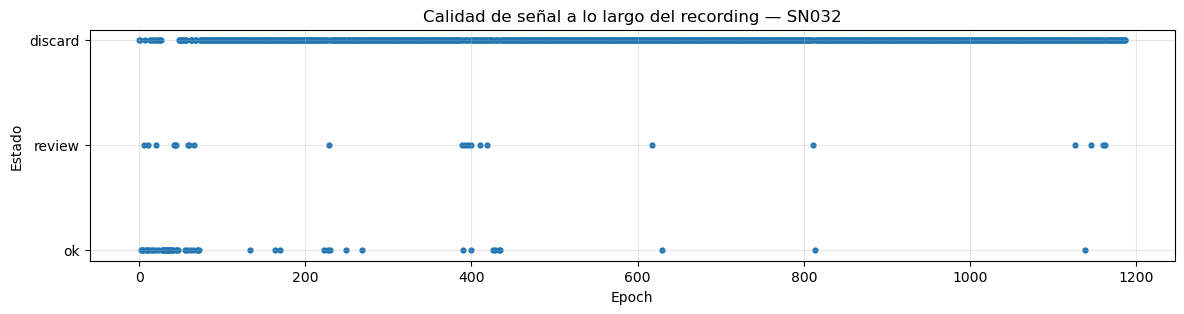

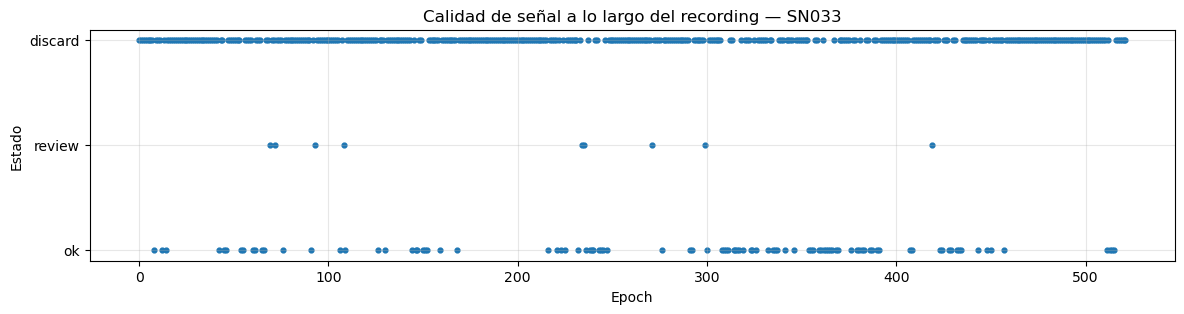

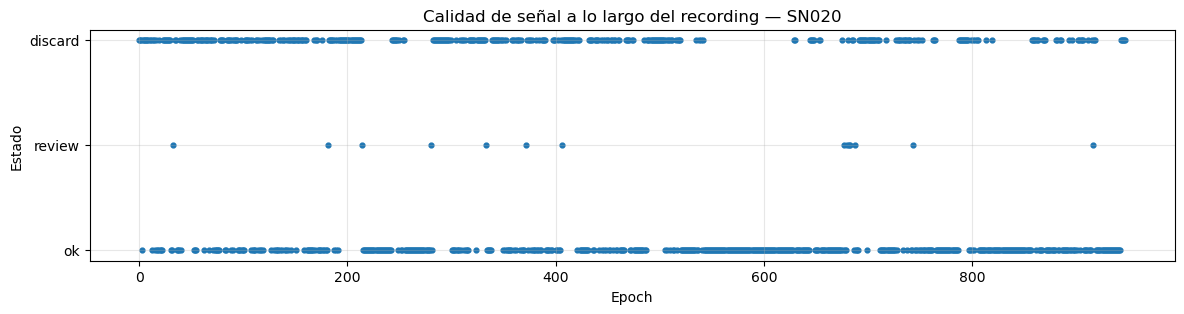

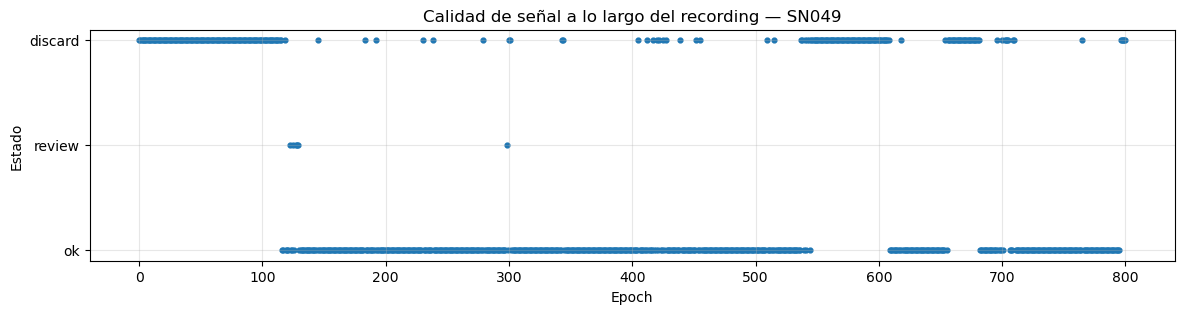

In [92]:
plot_subject_quality_timeline(
    "SN032",
    OUTPUT_PATH
)

plot_subject_quality_timeline(
    "SN033",
    OUTPUT_PATH
)

plot_subject_quality_timeline(
    "SN020",
    OUTPUT_PATH
)

plot_subject_quality_timeline(
    "SN049",
    OUTPUT_PATH
)

In [96]:
def summarize_subject_reasons(subject_id, output_path):

    quality_path = os.path.join(
        output_path,
        "quality_reports",
        f"{subject_id}_quality.csv"
    )

    df_subject = pd.read_csv(quality_path)

    print(f"Resumen de calidad — {subject_id}")

    display(
        df_subject["status"]
        .value_counts()
        .rename_axis("status")
        .reset_index(name="n_epochs")
    )

    print("\nMotivos de descarte:")

    display(
        df_subject[
            df_subject["status"] == "discard"
        ]["reasons"]
        .value_counts()
        .rename_axis("reason")
        .reset_index(name="n_epochs")
        .head(15)
    )

In [97]:
summarize_subject_reasons(
    "SN032",
    OUTPUT_PATH
)

summarize_subject_reasons(
    "SN033",
    OUTPUT_PATH
)

Resumen de calidad — SN032


,status,n_epochs
0,discard,1112
1,ok,54
2,review,22



Motivos de descarte:


,reason,n_epochs
0,"muchas muestras por encima del umbral, múltipl...",559
1,"muchas muestras por encima del umbral, múltipl...",440
2,"muchas muestras por encima del umbral, amplitu...",95
3,"múltiples canales EEG afectados, amplitud elev...",15
4,"muchas muestras por encima del umbral, amplitu...",3


Resumen de calidad — SN033


,status,n_epochs
0,discard,414
1,ok,99
2,review,9



Motivos de descarte:


,reason,n_epochs
0,"muchas muestras por encima del umbral, múltipl...",273
1,"muchas muestras por encima del umbral, múltipl...",81
2,"múltiples canales EEG afectados, amplitud elev...",36
3,"muchas muestras por encima del umbral, amplitu...",22
4,"muchas muestras por encima del umbral, amplitu...",2


## Verificación global del procesamiento

El pipeline procesó correctamente los 151 registros disponibles.

En total se analizaron `137243` epochs originales. Después del control de calidad:

```text
125633 epochs → ok
  2271 epochs → review
  9339 epochs → discard
```

Los epochs clasificados como `discard` representan aproximadamente el `6.80%` del total y fueron eliminados por presentar evidencia fuerte de mala adquisición, como amplitudes extremadamente altas, numerosos picos, segmentos planos prolongados o múltiples canales EEG afectados.

Los `2271` epochs marcados como `review` representan aproximadamente el `1.65%` del total. Estos fragmentos se conservaron en el dataset, pero quedaron identificados mediante una máscara para permitir su análisis posterior.

La suma de epochs `review` y `discard` coincide con los `11610` epochs sospechosos detectados previamente durante el análisis exploratorio. La nueva estrategia mantiene la detección original, pero evita eliminar automáticamente los casos ambiguos.

El dataset procesado conserva `127904` epochs, equivalentes aproximadamente al `93.20%` de los datos originales.


### Sujetos excluidos del modelado

Después del análisis de calidad se identificaron dos recordings con problemas severos y generalizados de adquisición:

```text
SN032 → 93.60% de epochs descartados
SN033 → 79.31% de epochs descartados

## 9. Visualización de epochs procesados por etapa del sueño

Para verificar visualmente el resultado del preprocesamiento, se selecciona un epoch representativo de cada etapa del sueño y se grafican sus siete canales.

Los ejemplos se toman únicamente de epochs clasificados como `ok`. Los epochs marcados como `review` se conservan en el dataset para análisis posteriores, pero no se utilizan en esta visualización inicial.

También se excluyen los sujetos `SN032` y `SN033`, ya que presentan problemas generalizados de adquisición.

El objetivo es inspeccionar si las señales procesadas mantienen patrones fisiológicos razonables después del filtrado, el resampling y la normalización.

Sujetos procesados disponibles: 149


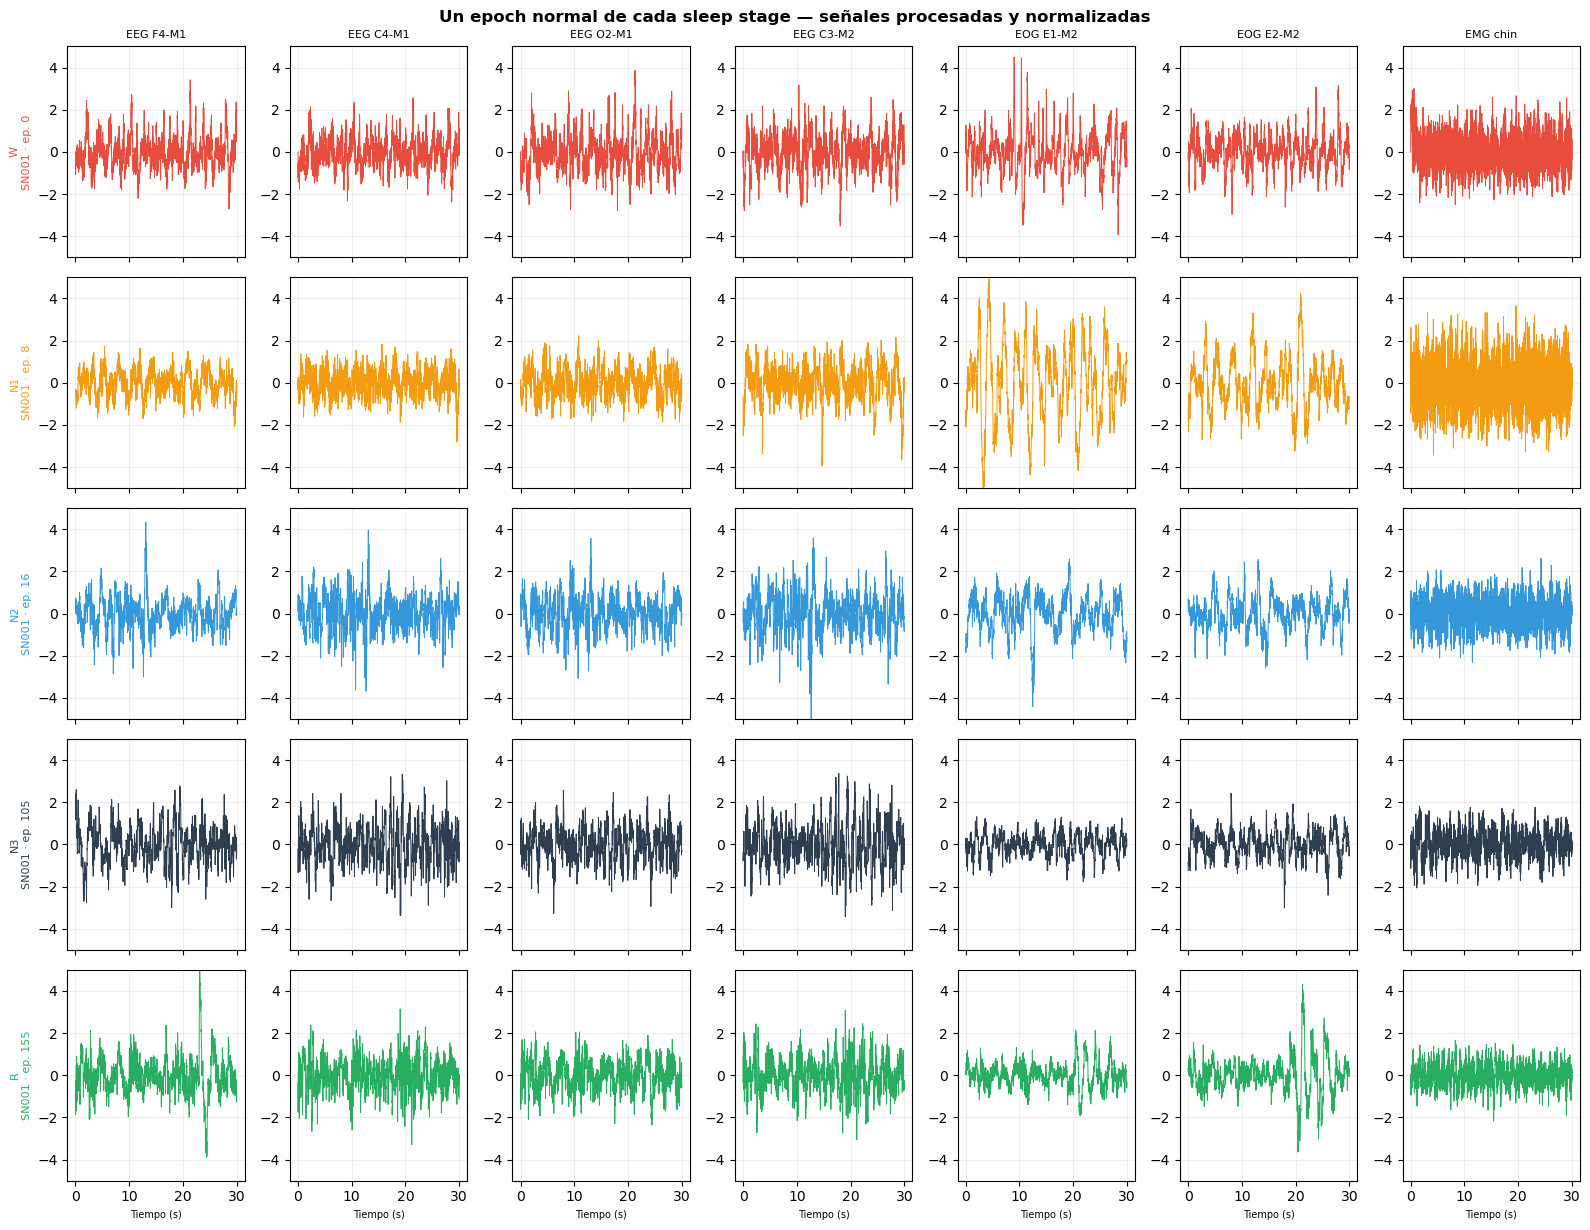

In [99]:
# ============================================================
# Mostrar un epoch normal de cada clase
# ============================================================

# Sujetos que no se utilizarán para modelado
EXCLUDED_SUBJECTS = {
    "SN032",
    "SN033",
}

# Traducir labels numéricos a nombres de etapas
inv_stage_map = {
    value: key
    for key, value in STAGE_MAP.items()
}

STAGE_COLORS = {
    "Sleep stage W":  "#e74c3c",
    "Sleep stage N1": "#f39c12",
    "Sleep stage N2": "#3498db",
    "Sleep stage N3": "#2c3e50",
    "Sleep stage R":  "#27ae60",
}

# Identificar archivos procesados disponibles
processed_subjects = sorted([
    file_name.replace(".npz", "")
    for file_name in os.listdir(OUTPUT_PATH)
    if (
        file_name.endswith(".npz")
        and file_name.replace(".npz", "") not in EXCLUDED_SUBJECTS
    )
])

print(f"Sujetos procesados disponibles: {len(processed_subjects)}")

# Guardaremos un ejemplo normal de cada etapa
representative_epochs = {}

channel_names = None
sfreq = None

# Recorrer sujetos hasta encontrar un epoch normal de cada clase
for subject_id in processed_subjects:

    file_path = os.path.join(
        OUTPUT_PATH,
        f"{subject_id}.npz"
    )

    data = np.load(
        file_path,
        allow_pickle=True
    )

    X_subject = data["X"]
    y_subject = data["y"]
    review_mask = data["review_mask"].astype(bool)
    source_epoch_index = data["source_epoch_index"]

    # Guardar metadata utilizando el primer sujeto válido
    if channel_names is None:
        channel_names = list(data["channel_names"])
        sfreq = float(data["sfreq"])

    # Utilizar únicamente epochs normales
    ok_mask = ~review_mask

    for label_int in sorted(inv_stage_map):

        # Si ya encontramos un ejemplo de esta clase, continuar
        if label_int in representative_epochs:
            continue

        candidate_indices = np.where(
            (y_subject == label_int) & ok_mask
        )[0]

        if len(candidate_indices) == 0:
            continue

        idx = candidate_indices[0]

        representative_epochs[label_int] = {
            "signal": X_subject[idx].copy(),
            "subject": subject_id,
            "source_epoch": int(source_epoch_index[idx]),
        }

    # Detener búsqueda cuando ya tenemos las cinco clases
    if len(representative_epochs) == len(STAGE_MAP):
        break

# Verificar que se hayan encontrado todas las etapas
missing_labels = [
    label_int
    for label_int in sorted(inv_stage_map)
    if label_int not in representative_epochs
]

if missing_labels:
    missing_names = [
        inv_stage_map[label]
        for label in missing_labels
    ]

    raise ValueError(
        f"No se encontraron epochs normales para: {missing_names}"
    )

# ============================================================
# Graficar señales
# ============================================================

unique_labels = sorted(representative_epochs)
n_stages = len(unique_labels)
n_channels = len(channel_names)

# Vector temporal correcto:
# 3000 muestras a 100 Hz → desde 0 hasta 29.99 segundos
n_samples = representative_epochs[unique_labels[0]]["signal"].shape[1]

time_seconds = np.arange(
    n_samples
) / sfreq

fig, axes = plt.subplots(
    n_stages,
    n_channels,
    figsize=(16, n_stages * 2.5),
    sharex=True
)

fig.suptitle(
    "Un epoch normal de cada sleep stage — señales procesadas y normalizadas",
    fontweight="bold",
    fontsize=12
)

for row, label_int in enumerate(unique_labels):

    stage_name = inv_stage_map[label_int]
    stage_short = stage_name.replace("Sleep stage ", "")
    color = STAGE_COLORS.get(stage_name, "gray")

    example = representative_epochs[label_int]

    epoch_signal = example["signal"]
    subject_id = example["subject"]
    source_epoch = example["source_epoch"]

    for col, channel_name in enumerate(channel_names):

        ax = axes[row, col]

        ax.plot(
            time_seconds,
            epoch_signal[col],
            lw=0.7,
            color=color
        )

        # Misma escala para facilitar comparación visual
        ax.set_ylim(-5, 5)

        ax.grid(
            True,
            alpha=0.2
        )

        if row == 0:
            ax.set_title(
                channel_name,
                fontsize=8
            )

        if col == 0:
            ax.set_ylabel(
                f"{stage_short}\n{subject_id} · ep. {source_epoch}",
                fontsize=8,
                color=color
            )

        if row == n_stages - 1:
            ax.set_xlabel(
                "Tiempo (s)",
                fontsize=7
            )

plt.tight_layout()
plt.show()

### Verificación visual de los epochs procesados

Se graficó un epoch normal de cada etapa del sueño después de aplicar el resampling, el filtrado y la normalización por canal.

Cada fila representa una etapa (`W`, `N1`, `N2`, `N3` y `R`) y cada columna corresponde a uno de los canales seleccionados: cuatro canales EEG, dos EOG y un EMG del mentón.

La inspección visual muestra señales con morfologías plausibles:

* En vigilia se observa una actividad relativamente irregular y mayor densidad en el canal EMG.
* En `N1` aparecen oscilaciones oculares visibles, compatibles con una etapa transicional.
* En `N2` se observan eventos transitorios en EEG que podrían estar asociados a patrones característicos de esta etapa.
* En `N3` predominan oscilaciones EEG más lentas y de mayor amplitud, consistentes con sueño profundo.
* En REM se distinguen movimientos oculares más marcados y una actividad muscular relativamente reducida.

Esta visualización no busca caracterizar completamente cada etapa, ya que se muestra solamente un ejemplo por clase. Su objetivo es comprobar que el pipeline conserve información fisiológica útil y no introduzca distorsiones evidentes.
